# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

In [37]:
import numpy as np
import pandas as pd
from itertools import chain
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych dla 1 tygodnia

### Ustawienie ziarna RNG

In [38]:
RNG_SEED = 20261110
rng= np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG:", RNG_SEED)

Ustawiono ziarno RNG: 20261110


### Zdefiniowanie "stałych"

In [39]:
LUMA_FULL="Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES=["Ceramika","Tekstylia","Biżuteria","Rękodzieło","Przetwory","Dekoracje","Stolarka","Masarstwo","Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [40]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base":[120,180,130,80,160,150,70,90,110],#średni lokalny popyt(szt./tydz.)
    "demand_tur_base":[60,40,80,30,90,30,50,40,80],#średni popyt turystyczny(szt./tydz.)
    "price_pln_base":[8,120,150,230,40,35,250,215,135],#średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni+turyści)*cena

In [41]:
catalog["revenue_avg_pln"]=(catalog["demand_loc_base"]+catalog["demand_tur_base"])*catalog["price_pln_base"]

In [42]:
display (catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [43]:
def determine_demand(catalog,rng,variance=0.15,boost_loc=0,boost_tur=0):
    df =catalog[["category","demand_loc_base","demand_tur_base"]].copy()
    eps_loc=np.clip(rng.normal(loc=1,scale=variance,size=len(df)),0.5,1.8)
    eps_tur=np.clip(rng.normal(loc=1,scale=variance,size=len(df)),0.5,1.8)
    df["demand_loc"]=(df["demand_loc_base"]*(1+boost_loc))*eps_loc
    df["demand_tur"]=(df["demand_tur_base"]*(1+boost_tur))*eps_tur
    df["demand_loc"]=np.maximum(df["demand_loc"].round().astype(int),0)
    df["demand_tur"]=np.maximum(df["demand_tur"].round().astype(int),0)
    return df[["category","demand_loc","demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [44]:
def count_revenue(catalog,demand_df):
    df=demand_df.merge(catalog[["category","price_pln_base"]],on="category",how="left")
    df["revenue_loc"]=df["demand_loc"]*df["price_pln_base"]
    df["revenue_tur"]=df["demand_tur"]*df["price_pln_base"]
    df["revenue_pln"]=df["revenue_loc"]+df["revenue_tur"]
    return df[["category","revenue_loc","revenue_tur","revenue_pln"]]

Generowanie danych tygodniuowych


In [45]:
def generate_weekly_data(catalog,rng,variance=0.15,boost_loc=0.0,boost_tur=0.0):
    demand_df=determine_demand(catalog,rng,variance=variance,boost_loc=boost_loc,boost_tur= boost_tur)
    revenue_df=count_revenue(catalog,demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych dla tyg 1

In [46]:
t1=generate_weekly_data(catalog,rng)
t1=t1.merge(catalog[["category","price_pln_base"]],on="category",how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN):",t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,960,504,1464,8
1,Tekstylia,22440,5520,27960,120
2,Biżuteria,20100,10950,31050,150
3,Rękodzieło,18170,6440,24610,230
4,Przetwory,7320,3760,11080,40
5,Dekoracje,3255,1260,4515,35
6,Stolarka,17500,15250,32750,250
7,Masarstwo,19350,9245,28595,215
8,Alkohole,14040,11205,25245,135


Łączny przychód w tygodniu 1 (PLN): 187269


## Analiza i wizualizacja danych -1 seria danych

Podstawowe wykresy

<Axes: >

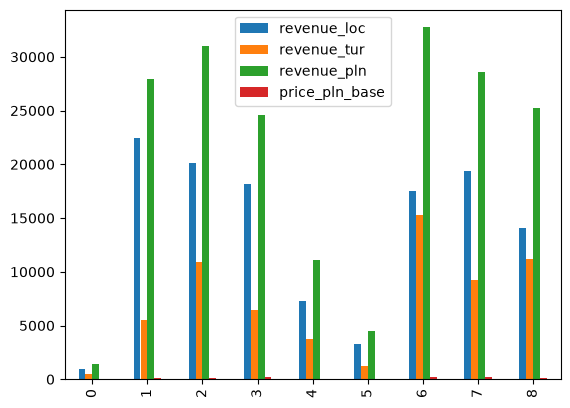

In [47]:
t1.plot.bar()

<Axes: >

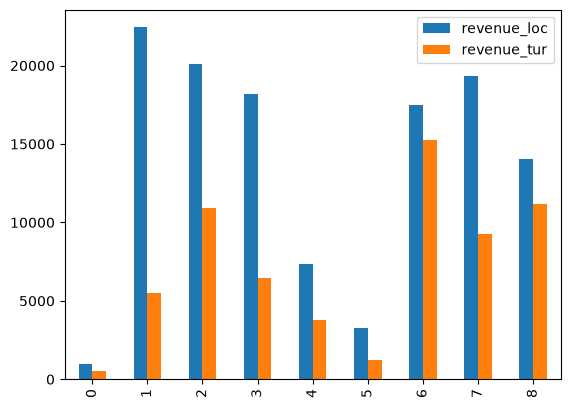

In [48]:
t1[["revenue_loc","revenue_tur"]].plot.bar()

<Axes: >

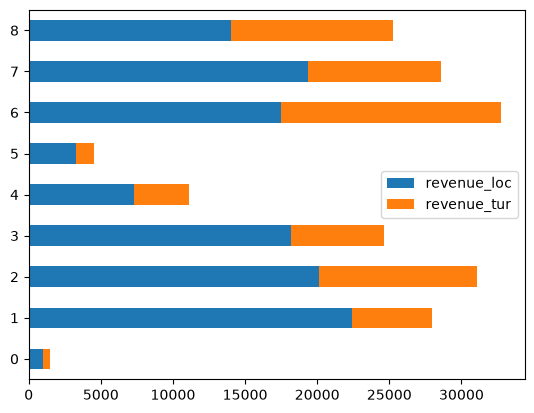

In [49]:
t1[["revenue_loc","revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

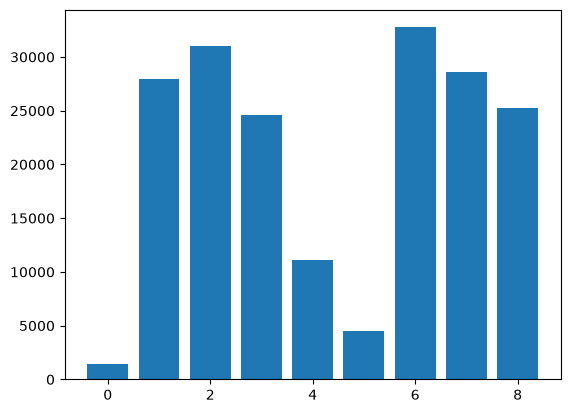

In [50]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

Jawne tworzenie i wyswietlanie wykresu

In [51]:
heights = t1["revenue_pln"]
categories = t1["category"]

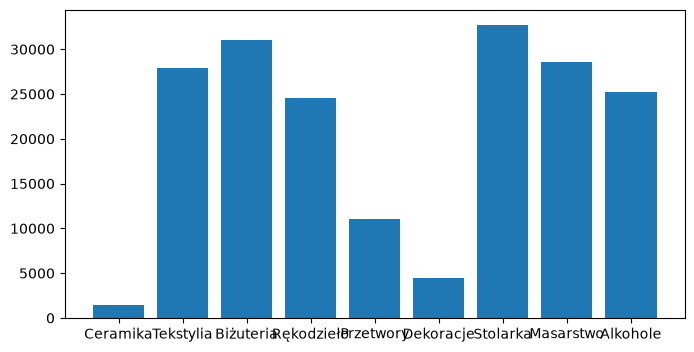

In [52]:
plt.figure(figsize=(8,4))
plt.bar(categories, heights)
plt.show()

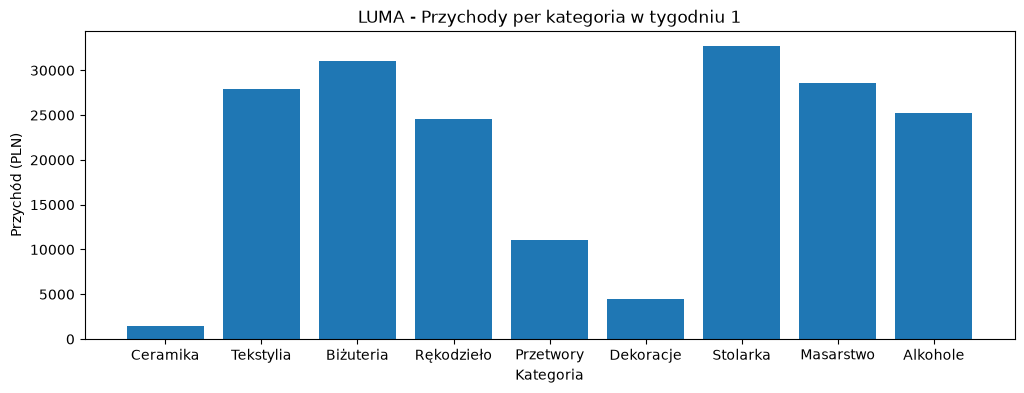

In [53]:
plt.figure(figsize=(12,4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

Etykiety wartości i formatowanie liczb

In [54]:
def format_pln(x:float)->str:
    return f"{int(round(x)):,}zł".replace(",","\u202f")

In [55]:
def pad_axis(factor=0.07):
    ymin,ymax = plt.ylim() #pobranie wartości min i max dla y
    pad = (ymax-ymin)*factor
    plt.ylim(ymin,ymax+pad) #ustalenie nowej wartości y max

In [56]:
def label_bars_pln(bars):
    for bar in bars:
        x=bar.get_x()+bar.get_width()/2
        y=bar.get_height()
        plt.text(x,y,format_pln(y),ha="center",va="bottom")

Formatowanie etykiet podziałki osi

In [57]:
def format_tys(x:float,decimals:int=0)->str:
    v=x/1000.0
    if decimals==0:
        s=f"{int(round(v)):,}".replace(",","\u202f")
    else:
        s=f"{v:,.{decimals}f}".replace(",","\u202f").replace(".",",")
    return s+"tys."

In [58]:
def format_mln(x:float,decimals:int=0)->str:
    v=x/1000000.0
    if decimals==0:
        s=f"{int(round(v)):,}".replace(",","\u202f")
    else:
        s=f"{v:,.{decimals}f}".replace(",","\u202f").replace(".",",")
    return s+"mln."

In [59]:
def format_yticks_tys():
    ypos,ylab_old=plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

In [60]:
print(format_tys(123456789.456))

123 457tys.


Sortowanie kategorii dla łatwiejszego porównania

In [61]:
t1_sorted=t1.sort_values("revenue_pln", ascending=False).reset_index()
categories=t1_sorted["category"]
heights=t1_sorted["revenue_pln"]

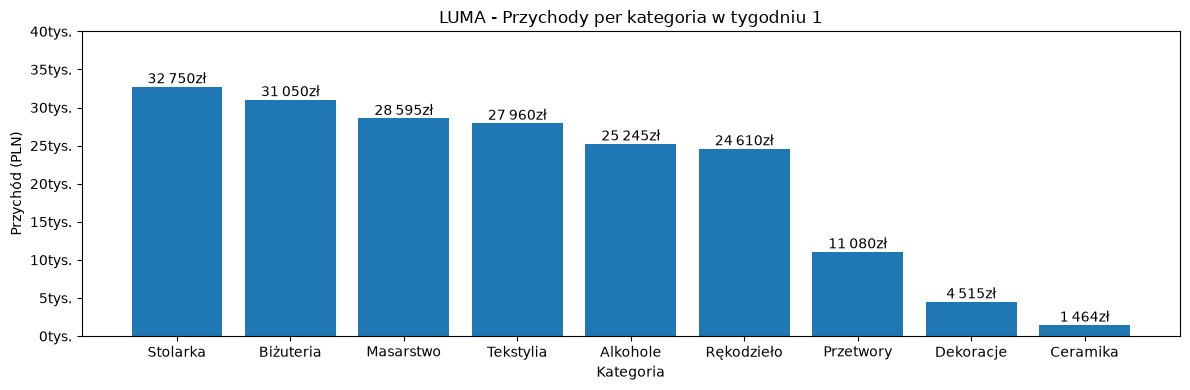

In [62]:
plt.figure(figsize=(12,4))
bars=plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_yticks_tys()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

Siatka w tle wykresu

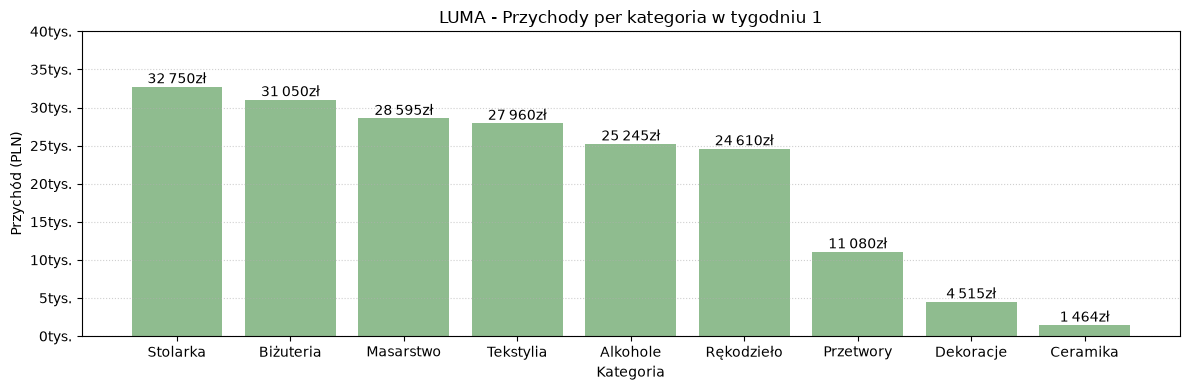

In [63]:
plt.figure(figsize=(12,4))
bars=plt.bar(categories, heights, color="darkseagreen")
pad_axis()
label_bars_pln(bars)
format_yticks_tys()
plt.grid(axis="y",linestyle=":",alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych -2 seria danych

### Wygenerowanie danych tygodniowych dla tygodnia 2

Mini-festiwal przyciąga klientów: lokalni +13%, turyści +20%

In [64]:
boost_loc = 0.13
boost_tur = 0.20

t2=generate_weekly_data(catalog,rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2=t2.merge(catalog[["category","price_pln_base"]],on="category",how="left")
print("Tydzień 2 - przychody per kategoria (PLN)")
display(t2)
print("Łączny przychód w tygodniu 1 :",format_pln(t1["revenue_pln"].sum()))
print("Łączny przychód w tygodniu 2 :",format_pln(t2["revenue_pln"].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,1192,464,1656,8
1,Tekstylia,23160,3000,26160,120
2,Biżuteria,21900,17700,39600,150
3,Rękodzieło,19550,8510,28060,230
4,Przetwory,8800,3120,11920,40
5,Dekoracje,5460,1050,6510,35
6,Stolarka,18250,13750,32000,250
7,Masarstwo,16985,12470,29455,215
8,Alkohole,18495,14310,32805,135


Łączny przychód w tygodniu 1 : 187 269zł
Łączny przychód w tygodniu 2 : 208 166zł


Przygotowanie danych do wykresów

In [65]:
categories=t1_sorted["category"]
t1_revenue_total = t1_sorted["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[categories]["revenue_pln"]
x_locs = np.arange(len(categories))
bar_width = 0.4
bar_half = bar_width/2

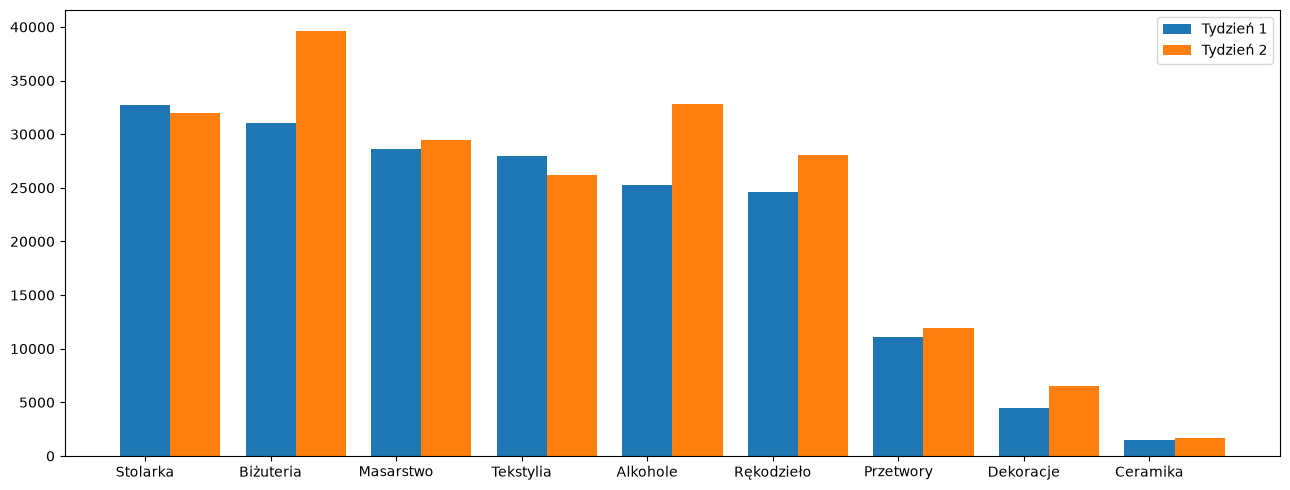

In [66]:
plt.figure(figsize=(13,5))
plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", tick_label=categories,)
plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2",)
plt.legend()
plt.tight_layout()
plt.show()

Łączne operowanie na seriach

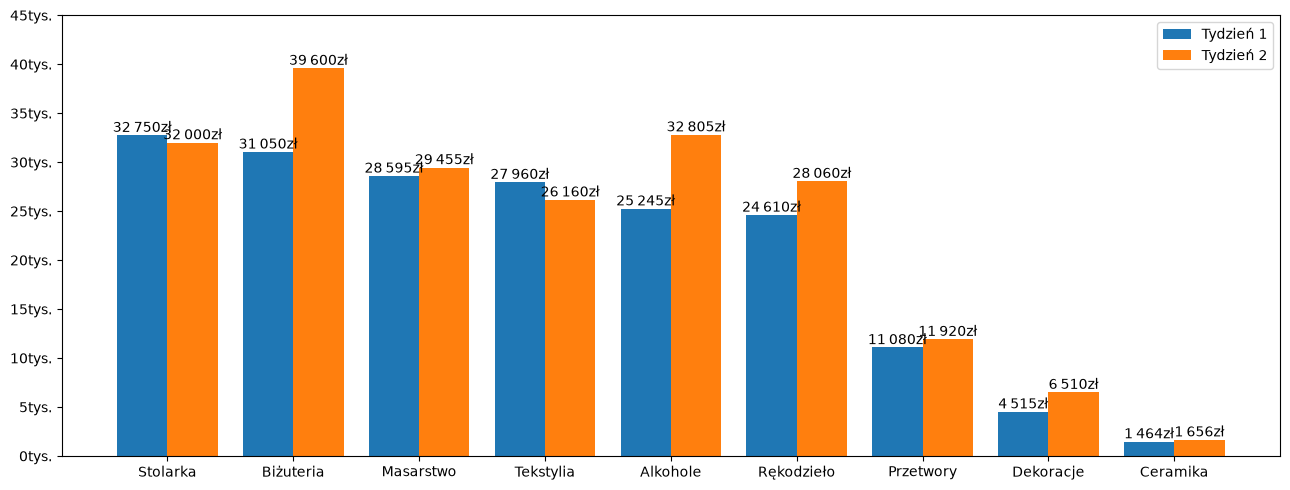

In [67]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1" )
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2")
plt.xticks(x_locs, categories)
pad_axis()
label_bars_pln(chain(bars_1,bars_2))
format_yticks_tys()
plt.legend()
plt.tight_layout()
plt.show()

Aktualizacja wyświetlania etykiet wartości

In [68]:
def format_sep(x:float)->str:
    return f"{int(round(x)):,}".replace(",","\u202f")

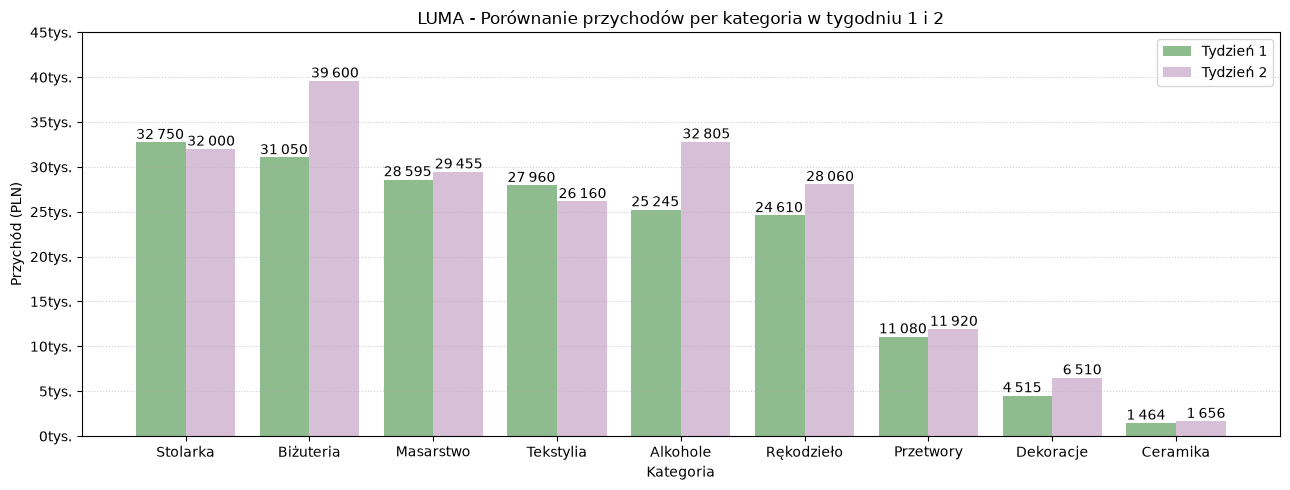

In [69]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", color="darkseagreen" )
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2", color="thistle")
plt.xticks(x_locs, categories)
pad_axis()
for b in bars_1:
    x,y = b.get_x(),b.get_height()
    plt.text(x, y, format_sep(y), ha='left', va='bottom')
for b in bars_2:
    x,y = b.get_x()+b.get_width(),b.get_height()
    plt.text(x, y, format_sep(y), ha='right', va='bottom')
format_yticks_tys()
plt.grid(axis="y",linestyle=":",alpha=0.6)
plt.title("LUMA - Porównanie przychodów per kategoria w tygodniu 1 i 2")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.legend()
plt.tight_layout()
plt.show()

## Analiza i wizualizaja danych - prezentacja zmian bezwzględnych

Przygotowanie różnic i procentowych zmian między tygodniami 1 i 2

In [70]:
order = CATEGORIES
t1_revenue_total = t1.set_index("category").loc[order]["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[order]["revenue_pln"]

base = t1_revenue_total
delta = t2_revenue_total - t1_revenue_total
pct = np.divide(
    delta, 
    base, 
    out=np.full_like(base, np.nan, dtype=float), 
    where=base!=0
)*100

t_delta = pd.DataFrame(
    {
        "category": order,
        "t1_pln": t1_revenue_total.astype(int),
        "t2_pln": t2_revenue_total.astype(int),
        "delta_pln": delta.astype(int),
        "delta_pct": np.round(pct, 1)
    }
).reset_index(drop=True)
display(t_delta)

,category,t1_pln,t2_pln,delta_pln,delta_pct
0,Ceramika,1464,1656,192,13.1
1,Tekstylia,27960,26160,-1800,-6.4
2,Biżuteria,31050,39600,8550,27.5
3,Rękodzieło,24610,28060,3450,14.0
4,Przetwory,11080,11920,840,7.6
5,Dekoracje,4515,6510,1995,44.2
6,Stolarka,32750,32000,-750,-2.3
7,Masarstwo,28595,29455,860,3.0
8,Alkohole,25245,32805,7560,29.9


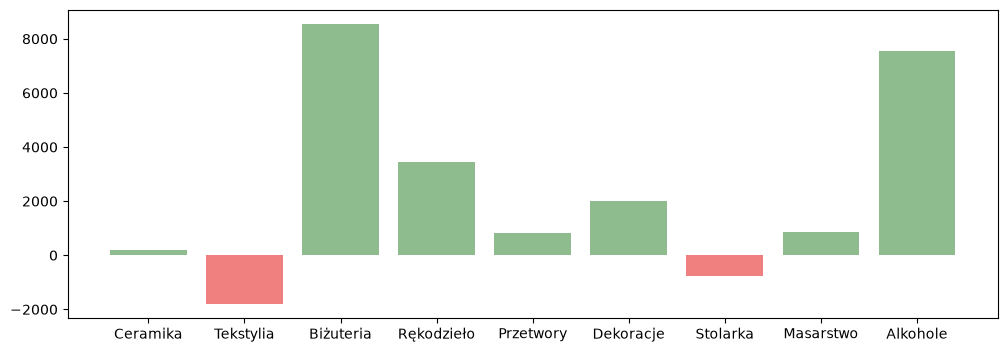

In [71]:
colors = ["darkseagreen" if v >= 0 else "lightcoral" for v in t_delta["delta_pln"]]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.show()

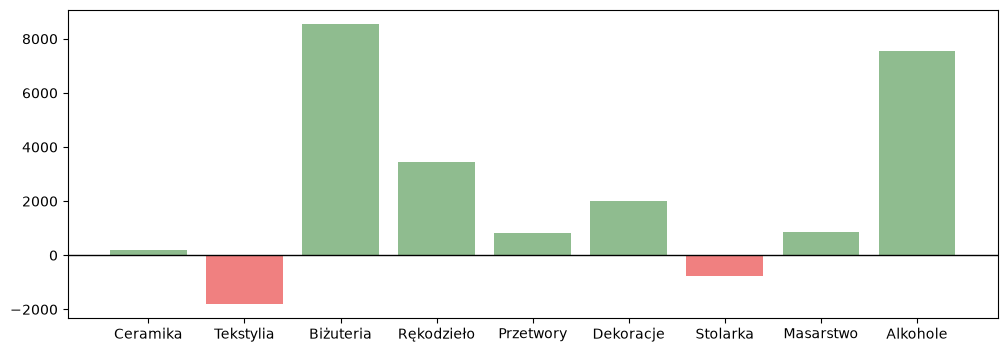

In [72]:
colors = ["darkseagreen" if v >= 0 else "lightcoral" for v in t_delta["delta_pln"]]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.show()

In [73]:
def format_sep_signed(x:float)->str:
    s=format_sep(abs(x))
    return("+" if x>=0 else"\u2212")+s

In [74]:
def pad_ylims(axes, factor=0.07):
    ymin,ymax = axes.get_ylim() #pobranie wartości min i max dla y
    pad = (ymax-ymin)*factor
    axes.set_ylim(ymin,ymax+pad) #ustalenie nowej wartości y max

In [75]:
def label_bars(axes,bars,values,formatter=format_sep_signed, offset_factor=0.02):
    ymin,ymax = axes.get_ylim()
    offset = (ymax-ymin)*offset_factor
    for b, v in zip(bars, values):
        x = b.get_x() + b.get_width()/2
        y = b.get_y() + b.get_height()
        label = formatter(v)
        va = "top" if v < 0 else "bottom"
        y_text = y - offset if v < 0 else y + offset
        axes.text(x, y_text, label, ha="center", va=va)

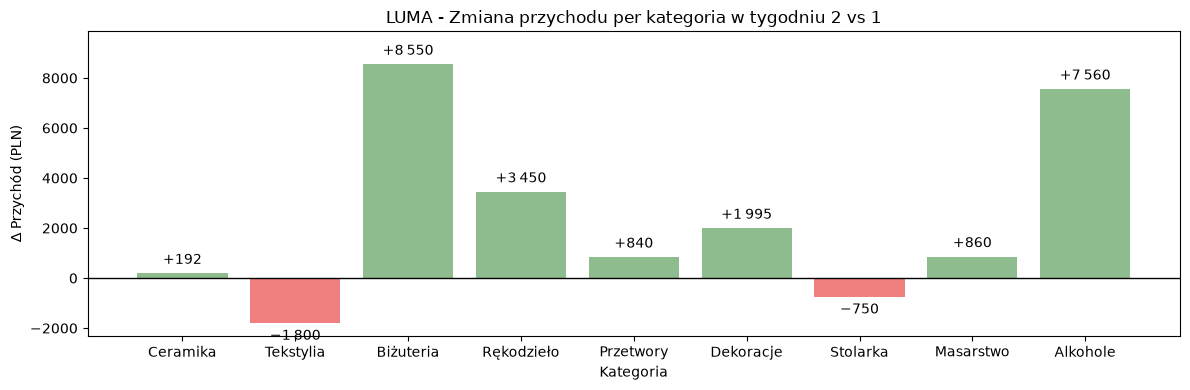

In [76]:
plt.figure(figsize=(12,4))
bars=plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pln"])
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana przychodu per kategoria w tygodniu 2 vs 1")
plt.xlabel("Kategoria")
plt.ylabel("\u2206 Przychód (PLN)")
plt.tight_layout()
plt.show()